# PyTorch: A Quick Tutorial

**PyTorch** is a Python library for deep learning. It gives us two main things:
1. **Tensors**: like NumPy arrays, but they can run on a **GPU**.
2. **Autograd**: PyTorch **computes gradients automatically**, so we never derive backprop by hand.

**Contents**
1. Tensors
2. Tensor operations
3. NumPy ↔ PyTorch
4. GPU
5. Autograd
6. Linear regression using only autograd
7. The same model with `nn` and `optim`
8. Common errors and how to fix them

In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt

print(torch.__version__)

2.14.1+cpu


## 1. Tensors

A **tensor** is a multi-dimensional array: a scalar (0-D), vector (1-D), matrix (2-D), or higher.
Every tensor has a **shape**, a **dtype** (data type) and a **device** (CPU or GPU).

In [2]:
torch.manual_seed(0)                       # same "random" numbers on every run

a = torch.tensor([1.0, 2.0, 3.0])          # from a Python list
b = torch.zeros(2, 3)                      # 2x3 of zeros
c = torch.ones(2, 3)                       # 2x3 of ones
d = torch.rand(2, 3)                       # uniform random in [0, 1)
e = torch.randn(2, 3)                      # random from a standard normal
f = torch.arange(0, 10, 2)                 # [0, 2, 4, 6, 8]

print(a)
print(d)
print("shape:", d.shape, "| dtype:", d.dtype, "| device:", d.device)

tensor([1., 2., 3.])
tensor([[0.4963, 0.7682, 0.0885],
        [0.1320, 0.3074, 0.6341]])
shape: torch.Size([2, 3]) | dtype: torch.float32 | device: cpu


## 2. Tensor operations
Most operations work exactly like NumPy.

In [3]:
x = torch.tensor([[1.0, 2.0], [3.0, 4.0]])
y = torch.tensor([[5.0, 6.0], [7.0, 8.0]])

print(x + y)          # element-wise addition
print(x * y)          # element-wise multiplication
print(x @ y)          # matrix multiplication (same as torch.matmul(x, y))
print(x.T)            # transpose
print(x.sum(), x.mean(), x.max())

tensor([[ 6.,  8.],
        [10., 12.]])
tensor([[ 5., 12.],
        [21., 32.]])
tensor([[19., 22.],
        [43., 50.]])
tensor([[1., 3.],
        [2., 4.]])
tensor(10.) tensor(2.5000) tensor(4.)


In [4]:
t = torch.arange(12)            # shape (12,)
print(t.reshape(3, 4))          # shape (3, 4)
print(t.reshape(3, -1).shape)   # -1 means "work it out": (3, 4)

m = t.reshape(3, 4)
print(m[0])                     # first row
print(m[:, 1])                  # second column
print(m[m > 5])                 # boolean indexing

v = torch.tensor([1.0, 2.0, 3.0])          # shape (3,)
print(v.unsqueeze(0).shape)                # add a dimension: (1, 3)
print(v.unsqueeze(1).shape)                # (3, 1)

tensor([[ 0,  1,  2,  3],
        [ 4,  5,  6,  7],
        [ 8,  9, 10, 11]])
torch.Size([3, 4])
tensor([0, 1, 2, 3])
tensor([1, 5, 9])
tensor([ 6,  7,  8,  9, 10, 11])
torch.Size([1, 3])
torch.Size([3, 1])


### Reductions along a dimension
`dim` says **which dimension gets collapsed**. `dim=0` works down the rows (one result per column); `dim=1` works across the columns (one result per row).

In [5]:
x = torch.tensor([[1.0, 2.0, 3.0],
                  [4.0, 5.0, 6.0]])      # shape (2, 3)

print(x.sum(dim=0))        # tensor([5., 7., 9.])   one value per column
print(x.sum(dim=1))        # tensor([ 6., 15.])     one value per row
print(x.argmax(dim=1))     # tensor([2, 2])         index of the largest value in each row

# typical use: turn a model's class scores into predicted classes
logits = torch.tensor([[2.0, 0.5, 1.0],
                       [0.1, 3.0, 0.2]])
print(logits.argmax(dim=1))   # tensor([0, 1])

tensor([5., 7., 9.])
tensor([ 6., 15.])
tensor([2, 2])
tensor([0, 1])


### Combining tensors
- `torch.cat` joins tensors along an **existing** dimension.
- `torch.stack` puts tensors on top of each other along a **new** dimension.

In [6]:
a = torch.zeros(2, 3)
b = torch.ones(2, 3)

print(torch.cat([a, b], dim=0).shape)   # (4, 3): more rows
print(torch.cat([a, b], dim=1).shape)   # (2, 6): more columns
print(torch.stack([a, b]).shape)        # (2, 2, 3): a new first dimension

torch.Size([4, 3])
torch.Size([2, 6])
torch.Size([2, 2, 3])


### Broadcasting
Tensors with different shapes can still be combined: PyTorch **stretches** dimensions of size 1 (or missing dimensions) to match.
Shapes are compared **from the right**; two dimensions fit if they are **equal** or one of them is **1**.

| Shapes | Result |
|---|---|
| `(4, 3)` and `(3,)` | `(4, 3)`: the vector is applied to every row |
| `(4, 1)` and `(1, 3)` | `(4, 3)` |
| `(4, 3)` and `(4,)` | error: 3 and 4 don't fit |

In [7]:
X = torch.rand(4, 3)
col_means = X.mean(dim=0)          # shape (3,)
X_centered = X - col_means         # (4, 3) - (3,): subtracts the mean from every row
print(X_centered.mean(dim=0))      # ≈ 0 for every column

tensor([2.9802e-08, 2.9802e-08, 1.4901e-08])


> **Small notes**
> - Methods ending in `_` change the tensor **in place**: `t.add_(1)`, `t.zero_()`.
> - `view` and `reshape` both change the shape, but `view` fails on some tensors (e.g. after a transpose). Just use `reshape`.

## 3. NumPy ↔ PyTorch

In [8]:
arr = np.array([1.0, 2.0, 3.0])
t = torch.from_numpy(arr)        # NumPy -> tensor (shares memory with arr)
back = t.numpy()                 # tensor -> NumPy

s = torch.tensor(3.5)
print(s.item())                  # a one-element tensor -> Python number

3.5


## 4. Running on a GPU
Move tensors (and later, models) to the GPU with `.to(device)`. All tensors in one operation must be on the **same device**.

In [9]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using:", device)

x = torch.rand(3, 3).to(device)
y = torch.rand(3, 3, device=device)      # or create it directly on the device
print((x @ y).device)

Using: cpu
cpu


## 5. Autograd: automatic gradients

If a tensor is created with `requires_grad=True`, PyTorch **records every operation** done with it. Calling `.backward()` on the result then computes the gradients (using backpropagation) and stores them in `.grad`.

Example: $y = x^2 + 3x$, so $\frac{dy}{dx} = 2x + 3$. At $x = 2$ this is $7$.

In [10]:
x = torch.tensor(2.0, requires_grad=True)
y = x**2 + 3*x

y.backward()          # compute dy/dx
print(x.grad)         # tensor(7.)

tensor(7.)


**Two things to remember**
- Gradients **accumulate**: calling `backward()` again **adds** to `.grad`. That is why training loops reset them every step.
- Wrap code that should **not** be tracked (weight updates, evaluation) in `torch.no_grad()`.

In [11]:
y = x**2 + 3*x
y.backward()
print(x.grad)         # tensor(14.) = 7 + 7, accumulated!

x.grad.zero_()        # reset
print(x.grad)

with torch.no_grad():
    z = x * 2
print(z.requires_grad)   # False: not tracked

tensor(14.)
tensor(0.)
False


### The computation graph, `detach()` and freezing
- Every result remembers the operation that created it in `grad_fn`. This recorded graph is what `backward()` walks through.
- `t.detach()` gives the same values with **no** gradient tracking (e.g. for plotting or converting to NumPy).
- Setting `requires_grad = False` on parameters **freezes** them, so they won't be updated during training.

In [12]:
x = torch.tensor(2.0, requires_grad=True)
y = x**2 + 3*x
print(y.grad_fn)               # <AddBackward0 ...>: y knows how it was computed

y_value = y.detach()
print(y_value.requires_grad)   # False

layer = torch.nn.Linear(3, 1)
for p in layer.parameters():
    p.requires_grad = False    # frozen: the optimiser will not change these weights

False


## 6. Linear regression using only autograd

Let's fit $y = wx + b$ to data generated from $y = 3x + 2$ + noise. Autograd computes the gradients; we do the gradient-descent update ourselves.

In [13]:
torch.manual_seed(0)
X = torch.rand(100, 1) * 10
y = 3 * X + 2 + torch.randn(100, 1)

w = torch.randn(1, requires_grad=True)
b = torch.zeros(1, requires_grad=True)
lr = 0.01

for epoch in range(1000):
    y_pred = X * w + b                     # 1. forward pass
    loss = ((y_pred - y) ** 2).mean()      # 2. loss (MSE)
    loss.backward()                        # 3. gradients

    with torch.no_grad():                  # 4. gradient-descent update
        w -= lr * w.grad
        b -= lr * b.grad
    w.grad.zero_()                         # 5. reset gradients
    b.grad.zero_()

    if epoch % 200 == 0:
        print(f"epoch {epoch:4d} | loss {loss.item():.3f}")

print(f"learned w = {w.item():.2f}, b = {b.item():.2f}   (true: 3, 2)")

epoch    0 | loss 253.637
epoch  200 | loss 0.913
epoch  400 | loss 0.807
epoch  600 | loss 0.793
epoch  800 | loss 0.791
learned w = 2.93, b = 2.32   (true: 3, 2)


## 7. The same model with `nn` and `optim`

PyTorch has ready-made building blocks for each step:
- `nn.Linear` holds the weights and computes $Wx + b$,
- `nn.MSELoss` computes the loss,
- `torch.optim.SGD` does the update and resets the gradients.

This gives the **standard training loop** used for every neural network:

learned w = 2.93, b = 2.33


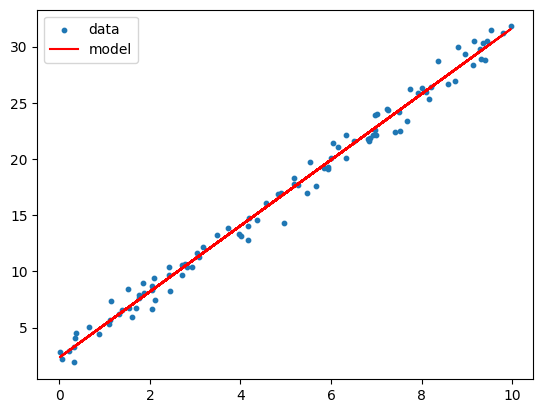

In [14]:
import torch.nn as nn

model = nn.Linear(in_features=1, out_features=1)
loss_fn = nn.MSELoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.01)

for epoch in range(1000):
    y_pred = model(X)                  # 1. forward pass
    loss = loss_fn(y_pred, y)          # 2. loss
    optimizer.zero_grad()              # 3. reset gradients
    loss.backward()                    # 4. backpropagation
    optimizer.step()                   # 5. update weights

print(f"learned w = {model.weight.item():.2f}, b = {model.bias.item():.2f}")

with torch.no_grad():
    plt.scatter(X, y, s=10, label="data")
    plt.plot(X, model(X), "r", label="model")
plt.legend()
plt.show()

## 8. Common errors and how to fix them

### (a) Wrong dtype
- NumPy arrays default to `float64`, but PyTorch layers use `float32`: convert with `.float()`.
- `CrossEntropyLoss` needs **class indices** as `long`; `BCEWithLogitsLoss` / `BCELoss` need **0/1 labels** as `float`.

In [15]:
arr = np.array([1.0, 2.0, 3.0])
t = torch.from_numpy(arr)
print(t.dtype)                       # torch.float64

layer = torch.nn.Linear(3, 1)        # weights are float32
# layer(t)                           # RuntimeError: dtype mismatch (Double vs Float)
print(layer(t.float()))              # fix: convert to float32

logits = torch.randn(4, 3)                    # 4 samples, 3 classes
labels = torch.tensor([0, 2, 1, 0])           # class indices (int64 = long)
print(torch.nn.CrossEntropyLoss()(logits, labels))

logit = torch.randn(4)                        # 4 samples, binary
y = torch.tensor([0, 1, 1, 0])                # int64
# torch.nn.BCEWithLogitsLoss()(logit, y)      # RuntimeError: target must be float
print(torch.nn.BCEWithLogitsLoss()(logit, y.float()))

torch.float64
tensor([-0.9738], grad_fn=<ViewBackward0>)
tensor(2.1499)
tensor(0.6507)


### (b) Silent broadcasting bug
A model usually outputs shape `(N, 1)`, while labels often have shape `(N,)`. Subtracting them broadcasts to `(N, N)`: **no error, just a wrong loss**. Make the shapes match (this is why the mushroom model uses `.squeeze(1)`).

In [16]:
y_pred = torch.rand(100, 1)          # model output
y_true = torch.rand(100)             # labels

print((y_pred - y_true).shape)               # torch.Size([100, 100])  wrong!
print((y_pred.squeeze(1) - y_true).shape)    # torch.Size([100])       correct

torch.Size([100, 100])
torch.Size([100])


### (c) Converting a tracked tensor to NumPy
`.numpy()` fails on a tensor that requires grad (or lives on the GPU). Detach it and move it to the CPU first.

In [17]:
w = torch.randn(3, requires_grad=True)
# w.numpy()                          # RuntimeError: Can't call numpy() on Tensor that requires grad
print(w.detach().cpu().numpy())      # fix

[-0.19013208  0.10280145 -0.3740789 ]


### (d) Other frequent ones

| Error / symptom | Cause | Fix |
|---|---|---|
| `Expected all tensors to be on the same device` | model on GPU, data on CPU (or the reverse) | `model.to(device)` and `x.to(device)` |
| `mat1 and mat2 shapes cannot be multiplied` | input size doesn't match `nn.Linear(in_features, ...)` | print `x.shape` and fix `in_features` |
| loss explodes or behaves strangely | forgot `optimizer.zero_grad()`, so gradients accumulate | call it every step |
| results change between runs | random initialisation and shuffling | `torch.manual_seed(0)` |

## Summary

| Task | Code |
|---|---|
| Create a tensor | `torch.tensor(...)`, `torch.zeros`, `torch.rand`, `torch.randn` |
| Shape / reshape | `t.shape`, `t.reshape(...)`, `t.unsqueeze(dim)` |
| Matrix multiply | `a @ b` |
| Reduce along a dimension | `x.sum(dim=0)`, `x.mean(dim=1)`, `x.argmax(dim=1)` |
| Combine tensors | `torch.cat([a, b], dim=0)`, `torch.stack([a, b])` |
| Change dtype | `t.float()`, `t.long()` |
| NumPy conversion | `torch.from_numpy(arr)`, `t.numpy()`, `t.item()` |
| Use the GPU | `t.to(device)`, `model.to(device)` |
| Track gradients | `requires_grad=True`, `loss.backward()`, `p.grad` |
| Don't track | `with torch.no_grad():`, `t.detach()` |
| Freeze parameters | `p.requires_grad = False` |
| Reproducible results | `torch.manual_seed(0)` |

**The training loop:** forward → loss → `zero_grad()` → `backward()` → `step()`

For a full neural network, plus layers, dropout, losses, data loaders and optimisers, see **NeuralNetworks.ipynb**.